In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
effect_sizes = pd.read_csv("results/RQ2/cohen_d.csv")
result_df = {"study": [], "base": [], "effect_desc": [], "effect_snippet": [], "effect_order": [], "inter_desc_order": [], "inter_desc_snippet": [], "inter_snippet_order": [], "inter_3": []}
for i in range(len(effect_sizes)): 
    study = effect_sizes["study"].iloc[i]
    base = effect_sizes["RQ2_no_order_no_snippets_no_desc"].iloc[i]
    snippet = effect_sizes["RQ2_no_order_no_desc"].iloc[i]
    order = effect_sizes["RQ2_no_snippets_no_desc"].iloc[i]
    desc = effect_sizes["RQ2_no_order_no_snippets"].iloc[i]
    snippet_order = effect_sizes["RQ2_no_desc"].iloc[i]
    snippet_desc = effect_sizes["RQ2_no_order"].iloc[i]
    order_desc = effect_sizes["RQ2_no_snippets"].iloc[i]
    order_snippet_desc = effect_sizes["RQ1"].iloc[i]
    snippet_effect = order_desc - order_snippet_desc 
    order_effect =  snippet_desc - order_snippet_desc
    desc_effect =  snippet_order - order_snippet_desc
    snippet_order_inter = desc - (order_snippet_desc+snippet_effect+order_effect)
    snippet_desc_inter = order - (order_snippet_desc+snippet_effect+desc_effect)
    order_desc_inter = snippet - (order_snippet_desc+order_effect+desc_effect)
    all_inter =  base - (order_snippet_desc+order_effect+desc_effect+snippet_effect+snippet_order_inter+snippet_desc_inter+order_desc_inter) 
    result_df["study"].append(study)
    result_df["base"].append(order_snippet_desc)
    result_df["effect_desc"].append(desc_effect)
    result_df["effect_order"].append(order_effect)
    result_df["effect_snippet"].append(snippet_effect)
    result_df["inter_desc_order"].append(order_desc_inter)
    result_df["inter_desc_snippet"].append(snippet_desc_inter)
    result_df["inter_snippet_order"].append(snippet_order_inter)
    result_df["inter_3"].append(all_inter)
res_df = pd.DataFrame(result_df)
res_df.to_csv("results/RQ2/substractive_effects.csv", index = False)

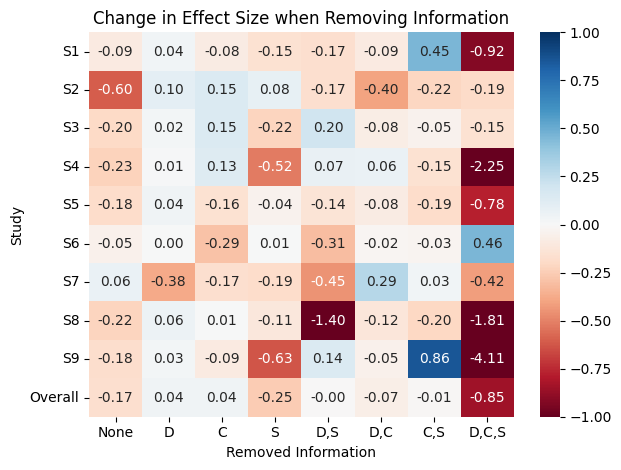

In [4]:
heatmap_df = res_df.set_index("study")
plt.figure(layout = "tight")
sns.heatmap(heatmap_df, annot = True, center = 0.0, cmap= "RdBu", vmin = -1.0, vmax= 1.0, fmt= ".2f")
plt.title("Change in Effect Size when Removing Information")
plt.xticks(plt.xticks()[0], ["None", "D", "C", "S", "D,S", "D,C", "C,S", "D,C,S"], rotation = 0)
plt.yticks(plt.yticks()[0], [f"S{i}" for i in range(1,10)] + ["Overall"])
plt.xlabel("Removed Information")
plt.ylabel("Study")
plt.savefig("images/heatmap_changes.pdf")